In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True,
               cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

%matplotlib inline
plt.rcParams.update({
    'font.size':         8,
    'figure.dpi':        300,
    'svg.fonttype':      'none',
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Roboto'],
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])

from src.notebook import load_notebook_data
from src.plotting import create_sydnor_sa_colormap
from src.gams import (fit_gam, get_series_colors, get_draw_order, style_ax,
                      compute_deriv_sa_corr, bootstrap_deriv_sa_corr)
from snaplab_tools.plotting.plotting import plot_correlation
from snaplab_tools.plotting.utils import get_my_colors

my_colors = get_my_colors()

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


In [2]:
projdir   = '/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales'
dataset   = 'HCP-D'
seg       = 'Schaefer4007'
n_nodes   = 400
brain_map = 'SA_Axis'

ce_params = (
    'c-1_T-1_rho-1_refstate-xf_initweights-one_nsteps-1000'
    '_lr-0.01_eigweight-1.0_regweight-0.0001_regtype-l2'
)

# HCP-D state counts
n_rest    = 5
n_task_km = 5
n_task_ct = 6
n_states  = n_rest + n_task_km + n_task_ct   # 16

# CARIT contrast labels — must match the order stored in the .npy file
task_ct_labels = ['go', 'miss', 'nogoCRLose', 'nogoCRWin', 'nogoFALose', 'nogoFAWin']
nogoCR_labels  = ['nogoCRLose', 'nogoCRWin']

# Absolute state indices for target conditions
go_ct_idx       = task_ct_labels.index('go')              # 0
go_abs_idx      = n_rest + n_task_km + go_ct_idx           # 10
nogoCR_ct_idxs  = [task_ct_labels.index(l) for l in nogoCR_labels]   # [2, 3]
nogoCR_abs_idxs = [n_rest + n_task_km + i for i in nogoCR_ct_idxs]   # [12, 13]

# Condition colors
REST_TO_REST_COLOR = my_colors['north_sea_green']
_c1 = np.array(mcolors.to_rgba(my_colors['starry_night_blue']))
_c2 = np.array(mcolors.to_rgba(my_colors['cinnamon']))
REST_TO_TASK_COLOR = mcolors.to_hex((_c1 + _c2) / 2)

# GAM parameters
n_splines   = 4
lam         = 0.1
demean      = True
residualize = True   # partial out sex + meanFD in all GAMs

# Load data

In [3]:
# ── Parcel metadata (Yeo 7-network labels) ────────────────────────────────────
parc_csv = os.path.join(
    projdir, 'data', 'supporting_data',
    'Schaefer2018_400Parcels_7Networks_order_FSLMNI152_1mm.Centroid_RAS.csv'
)
parc_centroids = pd.read_csv(parc_csv, index_col=1)
parc_centroids.drop(columns=['ROI Label'], inplace=True)
_yeo = (parc_centroids.index.str.strip()
        .str.replace('7Networks_LH_', '', regex=False)
        .str.replace('7Networks_RH_', '', regex=False))
yeo_systems = np.array([n.split('_')[0] for n in _yeo])

# ── Supporting data: SA axis + behavioral matching ────────────────────────────
notebook_data = load_notebook_data(
    dataset=dataset, which_modality='FMRI', use_7t=False,
    output_type='timescale_auc_zero_crossing_bp-0.01-0.08hz',
    use_resids=True, load_subject_data=False,
)
df_neuro = notebook_data['supporting_data']['df_neuro']
tp       = notebook_data['timescales_processor']
tp.match_registry_to_behavior()
df_beh   = tp.df_behavior_matched.copy()

# SA axis (ranked: 1 = sensorimotor, 400 = association)
sa_axis = sp.stats.rankdata(df_neuro[brain_map].values)

# ── Group-level NCT result ────────────────────────────────────────────────────
out_dir = os.path.join(projdir, 'results', dataset, 'nct')
nct_dir = os.path.join(projdir, 'data', 'nct', dataset)
ce_file = os.path.join(out_dir,
    f'{dataset}_{seg}_Am_optimal-optimized-energy_k-{n_states}_{ce_params}.npy')

log_args    = np.load(ce_file, allow_pickle=True).item()
adj_weights = -1 - log_args['optimized_weights']   # (n_states, n_states, n_nodes)
print(f'adj_weights: {adj_weights.shape}')

# Raw group-average weights per condition
off_diag_g         = ~np.eye(n_rest, dtype=bool)
rest_block_g       = adj_weights[:n_rest, :n_rest, :]
grp_rest_to_rest   = rest_block_g[off_diag_g, :].mean(axis=0)
grp_rest_to_go     = adj_weights[:n_rest, go_abs_idx,     :].mean(axis=0)
grp_rest_to_nogoCR = adj_weights[:n_rest][:, nogoCR_abs_idxs, :].mean(axis=(0, 1))
grp_rest_to_task   = (grp_rest_to_go + grp_rest_to_nogoCR) / 2   # go + nogoCR average

for lbl, w in [('rest-to-rest',   grp_rest_to_rest),
               ('rest-to-go',     grp_rest_to_go),
               ('rest-to-nogoCR', grp_rest_to_nogoCR),
               ('rest-to-task',   grp_rest_to_task)]:
    print(f'  {lbl}: mean={w.mean():.4f}  range=[{w.min():.3f}, {w.max():.3f}]')

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-D
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/processed
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       652 subjects

	Initialized Timescales for dataset: HCP-D
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 2760 scans from scan_registry_HCP-D.csv


Loading metric_tsnr: 100%|██████████| 2760/2760 [00:00<00:00, 7185.68it/s]


2760
timescale_auc_zero_crossing_bp-0.01-0.08hz


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz: 100%|██████████| 2760/2760 [00:00<00:00, 7760.40it/s]


2760


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz_resids: 100%|██████████| 2760/2760 [00:00<00:00, 8016.14it/s]


2760
Number of subjects: 552
adj_weights: (16, 16, 400)
  rest-to-rest: mean=-2.2181  range=[-2.588, -2.005]
  rest-to-go: mean=-2.2600  range=[-2.888, -0.893]
  rest-to-nogoCR: mean=-2.2359  range=[-2.858, -0.974]
  rest-to-task: mean=-2.2480  range=[-2.873, -0.933]


In [4]:
# ── Subject-level NCT data ────────────────────────────────────────────────────
subj_dir  = os.path.join(out_dir, 'subjects')
adj_ids   = np.loadtxt(
    os.path.join(nct_dir, f'{dataset}_{seg}_adjacency_subject_ids.txt'),
    dtype=str
)
n_adj = len(adj_ids)

subj_tmpl = (
    f'{dataset}_{seg}-adj-{{idx}}_optimal-optimized-energy'
    f'_k-{n_states}_{ce_params}.npy'
)

opt_w_subj = np.full((n_adj, n_states, n_states, n_nodes), np.nan)
loaded     = np.zeros(n_adj, dtype=bool)

for idx in range(n_adj):
    fp = os.path.join(subj_dir, subj_tmpl.format(idx=idx))
    if os.path.exists(fp):
        dd = np.load(fp, allow_pickle=True).item()
        opt_w_subj[idx] = dd['optimized_weights']
        loaded[idx] = True

adj_w = -1 - opt_w_subj   # self-inhibition weights: (n_adj, n_states, n_states, n_nodes)
print(f'Loaded {loaded.sum()} / {n_adj} subjects  ({(~loaded).sum()} missing)')

# Per-subject condition weights: (n_adj, n_nodes)
off_diag_s  = ~np.eye(n_rest, dtype=bool)               # (n_rest, n_rest) bool mask
rr_block_s  = adj_w[:, :n_rest, :n_rest, :]             # (n_adj, n_rest, n_rest, n_nodes)
subj_rest_to_rest = (
    rr_block_s.reshape(n_adj, n_rest * n_rest, n_nodes)
    [:, off_diag_s.ravel(), :]
    .mean(axis=1)
)                                                        # (n_adj, n_nodes)

subj_rest_to_go     = adj_w[:, :n_rest, go_abs_idx, :].mean(axis=1)
subj_rest_to_nogoCR = adj_w[:, :n_rest][:, :, nogoCR_abs_idxs, :].mean(axis=(1, 2))
subj_rest_to_task   = (subj_rest_to_go + subj_rest_to_nogoCR) / 2   # (n_adj, n_nodes)

# Behavioral covariates aligned to adj_ids order
def _beh(col):
    if col not in df_beh.columns:
        return np.full(n_adj, np.nan)
    return np.array([
        df_beh.at[s, col] if s in df_beh.index else np.nan
        for s in adj_ids
    ])

ages    = _beh('age')
sexes   = _beh('sex')
meanFDs = _beh('meanFD')
valid   = loaded & ~np.isnan(ages) & ~np.isnan(sexes) & ~np.isnan(meanFDs)
print(f'Valid subjects for developmental analysis: {valid.sum()}')

Loaded 546 / 546 subjects  (0 missing)
Valid subjects for developmental analysis: 546


# Fit GAMs

In [5]:
ages_v   = ages[valid]
sexes_v  = sexes[valid]
mFDs_v   = meanFDs[valid]
nuisance = np.column_stack([sexes_v, mFDs_v]) if residualize else None
x_grid   = np.linspace(ages_v.min(), ages_v.max(), 200)

# ── Whole-brain mean weights per subject ──────────────────────────────────────
rr_wbrain = subj_rest_to_rest[valid].mean(axis=1)   # (n_valid,) mean over regions
rt_wbrain = subj_rest_to_task[valid].mean(axis=1)   # (n_valid,)

# ── SA decile binning ─────────────────────────────────────────────────────────
n_deciles     = 10
decile_labels = pd.qcut(sa_axis, n_deciles, labels=False)   # (n_nodes,) int 0–9
cmap_sa       = create_sydnor_sa_colormap()
series_colors = get_series_colors('decile', n_deciles, cmap_sa)
draw_order    = get_draw_order('decile', n_deciles)

# REST→task decile-averaged weights per subject: (n_valid, n_deciles)
rt_dec = subj_rest_to_task[valid]   # (n_valid, n_nodes)
dec_w  = np.full((rt_dec.shape[0], n_deciles), np.nan)
for d in range(n_deciles):
    dec_w[:, d] = rt_dec[:, decile_labels == d].mean(axis=1)

# SA-decile GAM fits: pred and deriv matrices (n_deciles, n_grid)
dec_pred  = np.full((n_deciles, len(x_grid)), np.nan)
dec_deriv = np.full((n_deciles, len(x_grid)), np.nan)
for d in range(n_deciles):
    y = dec_w[:, d].copy()
    if demean:
        y -= np.nanmean(y)
    pred, _, _, deriv, _ = fit_gam(
        ages_v, y, x_grid, n_splines=n_splines, lam=lam, nuisance=nuisance)
    dec_pred[d]  = pred
    dec_deriv[d] = deriv
print('SA-decile GAMs done.')

# ── Regional GAMs for REST→task: (n_nodes, n_grid) ───────────────────────────
print('Fitting regional GAMs ...')
reg_w     = subj_rest_to_task[valid]   # (n_valid, n_nodes)
reg_pred  = np.full((n_nodes, len(x_grid)), np.nan)
reg_deriv = np.full((n_nodes, len(x_grid)), np.nan)
for i in range(n_nodes):
    y = reg_w[:, i].copy()
    if demean:
        y -= np.nanmean(y)
    pred, _, _, deriv, _ = fit_gam(
        ages_v, y, x_grid, n_splines=n_splines, lam=lam, nuisance=nuisance)
    reg_pred[i]  = pred
    reg_deriv[i] = deriv
print('Regional GAMs done.')

# Pearson r(SA axis, regional GAM derivative) at each age grid point: (n_grid,)
r_deriv = compute_deriv_sa_corr(reg_deriv, sa_axis, method='pearson')
print('SA-axis × derivative correlation curve computed.')

SA-decile GAMs done.
Fitting regional GAMs ...
Regional GAMs done.
SA-axis × derivative correlation curve computed.


In [6]:
# ── Bootstrap 95% CI for r(SA axis × regional GAM derivative) ────────────────
# reg_w: (n_valid, n_nodes) REST→task weights, already valid-masked
boot_curves = bootstrap_deriv_sa_corr(
    reg_w, ages_v, sa_axis, x_grid,
    n_splines=n_splines, lam=lam, demean=demean, nuisance=nuisance,
    n_boot=500, method='pearson', random_state=42,
)
r_ci_lo = np.nanpercentile(boot_curves, 2.5,  axis=0)   # (n_grid,)
r_ci_hi = np.nanpercentile(boot_curves, 97.5, axis=0)   # (n_grid,)
print(f'Bootstrap done. 95% CI at age midpoint: [{r_ci_lo[100]:.3f}, {r_ci_hi[100]:.3f}]')

Bootstrap:   0%|          | 0/500 [00:00<?, ?it/s]

Bootstrap done. 95% CI at age midpoint: [0.015, 0.123]


/home/lindenmp/anaconda3/envs/intrinsic_neural_timescales/lib/python3.11/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


# Figure 5

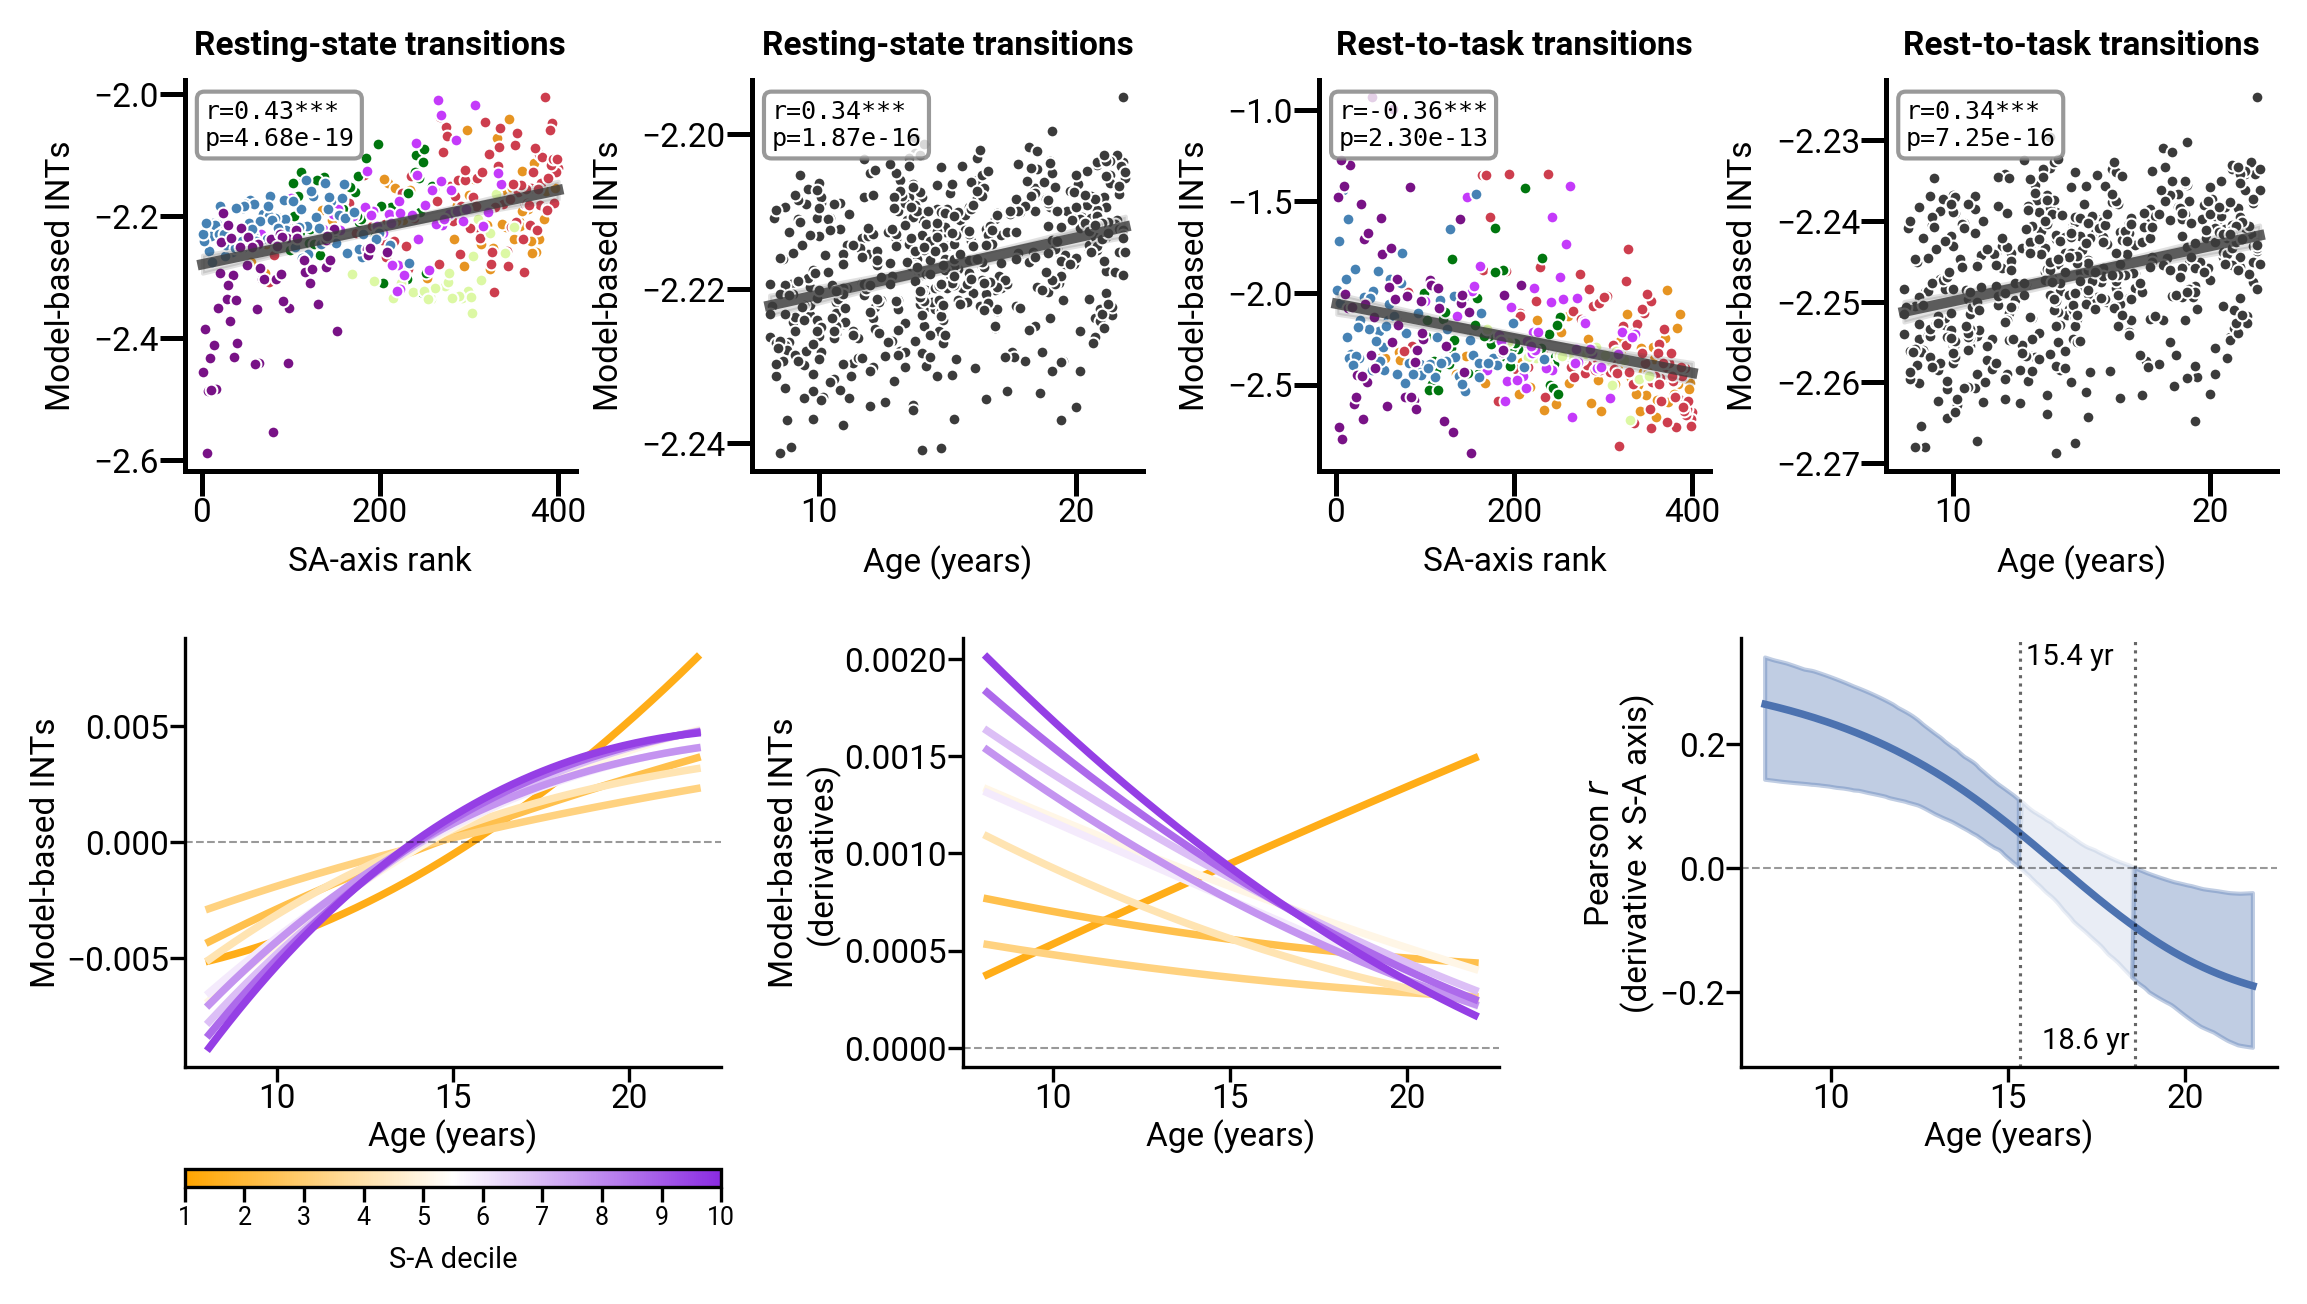

In [7]:
lw = 1.8

# ── Layout ────────────────────────────────────────────────────────────────────
# Row 1 (4 panels): SA×RR scatter, Age×RR scatter, SA×RT scatter, Age×RT scatter
# Row 2 (3 panels): SA-decile GAM pred, SA-decile deriv, r(SA×deriv) vs age
fig = plt.figure(figsize=(9, 5), dpi=300)
outer_gs = GridSpec(2, 1, figure=fig, height_ratios=[1.0, 1.2], hspace=0.0)

gs_r1 = GridSpecFromSubplotSpec(1, 4, subplot_spec=outer_gs[0], wspace=0.45)
gs_r2 = GridSpecFromSubplotSpec(1, 3, subplot_spec=outer_gs[1], wspace=0.45)

ax_r1 = [fig.add_subplot(gs_r1[0, i]) for i in range(4)]
ax_r2 = [fig.add_subplot(gs_r2[0, i]) for i in range(3)]

# ── Row 1: scatter panels ─────────────────────────────────────────────────────
# Panel 0: SA axis × REST→REST (group-level, Yeo-colored)
plot_correlation(
    pd.Series(sa_axis,          name='SA-axis rank'),
    pd.Series(grp_rest_to_rest, name='Model-based INTs'),
    ax_r1[0],
    method='pearson',
    size=8, alpha=1.0, show_confidence=True, grid=False,
    data_group=yeo_systems, data_group_cmap='yeo7',
    show_colorbar=False,
)
ax_r1[0].set_title('Resting-state transitions', fontsize=8, fontweight='bold')

# Panel 1: Age × REST→REST (subject-level, whole-brain mean)
plot_correlation(
    pd.Series(ages_v,    name='Age (years)'),
    pd.Series(rr_wbrain, name='Model-based INTs'),
    ax_r1[1],
    method='pearson',
    size=8, alpha=1.0, show_confidence=True, grid=False,
)
ax_r1[1].set_title('Resting-state transitions', fontsize=8, fontweight='bold')

# Panel 2: SA axis × REST→task (group-level, Yeo-colored)
plot_correlation(
    pd.Series(sa_axis,          name='SA-axis rank'),
    pd.Series(grp_rest_to_task, name='Model-based INTs'),
    ax_r1[2],
    method='pearson',
    size=8, alpha=1.0, show_confidence=True, grid=False,
    data_group=yeo_systems, data_group_cmap='yeo7',
    show_colorbar=False,
)
ax_r1[2].set_title('Rest-to-task transitions', fontsize=8, fontweight='bold')

# Panel 3: Age × REST→task (subject-level, whole-brain mean)
plot_correlation(
    pd.Series(ages_v,    name='Age (years)'),
    pd.Series(rt_wbrain, name='Model-based INTs'),
    ax_r1[3],
    method='pearson',
    size=8, alpha=1.0, show_confidence=True, grid=False,
)
ax_r1[3].set_title('Rest-to-task transitions', fontsize=8, fontweight='bold')

for ax in ax_r1:
    ax.set_box_aspect(1)
    ax.tick_params(labelsize=8, pad=0.25)

# ── Row 2: GAM line panels ────────────────────────────────────────────────────
# Panel 0: SA-decile GAM predictions (REST→task)
for dec in draw_order:
    ax_r2[0].plot(x_grid, dec_pred[dec], color=series_colors[dec], lw=lw)
style_ax(ax_r2[0], 'Age (years)', 'Model-based INTs', None, demean=demean)
ax_r2[0].set_box_aspect(0.8)

# Panel 1: SA-decile temporal derivatives (REST→task)
for dec in draw_order:
    ax_r2[1].plot(x_grid, dec_deriv[dec], color=series_colors[dec], lw=lw)
style_ax(ax_r2[1], 'Age (years)', 'Model-based INTs\n(derivatives)', None, demean=demean)
ax_r2[1].set_box_aspect(0.8)

# Panel 2: r(SA axis × regional GAM derivative) vs age, with bootstrap 95% CI
_c = '#4C72B0'
# Dark shade where CI is entirely above OR below zero; faint where it straddles zero
_sig = (r_ci_lo > 0) | (r_ci_hi < 0)
ax_r2[2].fill_between(x_grid, r_ci_lo, r_ci_hi,
                      where=_sig,  color=_c, alpha=0.35, interpolate=True)
ax_r2[2].fill_between(x_grid, r_ci_lo, r_ci_hi,
                      where=~_sig, color=_c, alpha=0.12, interpolate=True)
ax_r2[2].plot(x_grid, r_deriv, color=_c, lw=lw)
ax_r2[2].axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)

# Annotate significance boundaries.
# r_ci_lo > 0  → positive significance: label at top   (y=0.99, va='top')
# r_ci_hi < 0  → negative significance: label at bottom (y=0.03, va='bottom')
for bound_arr, sig_mask, y_pos, y_va in [
    (r_ci_lo, r_ci_lo > 0, 0.99, 'top'),
    (r_ci_hi, r_ci_hi < 0, 0.03, 'bottom'),
]:
    _diffs = np.diff(sig_mask.astype(int))
    for idx in np.where(_diffs)[0]:
        a0, a1 = bound_arr[idx], bound_arr[idx + 1]
        cross_age = x_grid[idx] + (-a0 / (a1 - a0)) * (x_grid[idx + 1] - x_grid[idx])
        ax_r2[2].axvline(cross_age, color='k', lw=0.75, ls=':', alpha=0.6)
        if _diffs[idx] > 0:   # entering significance → label on left of line
            ha, xpos = 'right', cross_age - 0.15
        else:                  # exiting significance  → label on right of line
            ha, xpos = 'left',  cross_age + 0.15
        ax_r2[2].text(xpos, y_pos, f'{cross_age:.1f} yr',
                      ha=ha, va=y_va, fontsize=7, color='k',
                      transform=ax_r2[2].get_xaxis_transform())

ax_r2[2].set_xlabel('Age (years)', fontsize=8, labelpad=1)
ax_r2[2].set_ylabel(f'Pearson $r$\n(derivative \u00d7 S-A axis)', fontsize=8, labelpad=1)
ax_r2[2].tick_params(labelsize=8, pad=0.25)
ax_r2[2].spines[['top', 'right']].set_visible(False)
ax_r2[2].set_box_aspect(0.8)

# ── SA-decile colorbar: below row 2, panel 0 ──────────────────────────────────
# x-extent: axes data box (no tick labels); y-clearance: full tightbbox (includes labels)
fig.canvas.draw()
renderer    = fig.canvas.get_renderer()
fw, fh      = np.array(fig.get_size_inches()) * fig.dpi
bbox_pred   = ax_r2[0].get_window_extent(renderer=renderer)
tight_pred  = ax_r2[0].get_tightbbox(renderer=renderer)
cbar_h_frac = 0.012
pad_frac    = 0.010
ax_cbar_sa  = fig.add_axes([
    bbox_pred.x0    / fw,
    tight_pred.y0   / fh - pad_frac - cbar_h_frac,
    bbox_pred.width / fw,
    cbar_h_frac,
])
norm_sa = mcolors.Normalize(vmin=1, vmax=n_deciles)
sm_sa   = plt.cm.ScalarMappable(cmap=cmap_sa, norm=norm_sa)
sm_sa.set_array([])
cb_sa = fig.colorbar(sm_sa, cax=ax_cbar_sa, orientation='horizontal')
cb_sa.set_label('S-A decile', fontsize=7)
cb_sa.set_ticks(list(range(1, n_deciles + 1)))
cb_sa.ax.tick_params(labelsize=6, pad=1)

fig.savefig(os.path.join(out_dir, 'fig5.svg'),
            bbox_inches='tight', pad_inches=0.01)
plt.show()